# TP 3 — Prompting

**Cours NLP et Transformers — CY Tech**

Même tâche que les TP 1 et 2, mais sans entraîner de modèle.

1. écrire le prompt
2. charger un LLM déjà fait
3. lire le nom dans sa réponse
4. évaluer, et comparer à la logistique


## 0. Environnement

`Qwen/Qwen2.5-0.5B-Instruct`, assez petit pour le CPU. `do_sample=False` : la même question donne toujours la même réponse.


In [1]:
import re
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from transformers import AutoModelForCausalLM, AutoTokenizer

RANDOM_STATE = 42  # même découpage que le TP 2
np.random.seed(RANDOM_STATE)
print("torch", torch.__version__)


torch 2.8.0


## 1. Les données

Même parser et même découpage. Les exemples du prompt viennent du train, pas du test.


In [2]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
urllib.request.urlretrieve(URL, "input.txt")
texte = open("input.txt", encoding="utf-8").read()


def parser_repliques(txt):
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


def nettoyer(phrase):
    return " ".join(re.findall(r"[a-z]+(?:'[a-z]+)?", phrase.lower()))


df = parser_repliques(texte)
df["n_mots"] = df["replique"].str.split().str.len()
top = df["locuteur"].value_counts().head(5).index  # les 5 plus bavards
donnees = df[df["locuteur"].isin(top)].query("n_mots >= 5").copy()
donnees["propre"] = donnees["replique"].map(nettoyer)
donnees = donnees[donnees["propre"].str.len() > 0].reset_index(drop=True)

X_reste, X_test, y_reste, y_test = train_test_split(
    donnees["propre"], donnees["locuteur"],
    test_size=0.20, stratify=donnees["locuteur"], random_state=RANDOM_STATE,
)
X_train, X_val, y_train, y_val = train_test_split(
    X_reste, y_reste, test_size=0.20, stratify=y_reste, random_state=RANDOM_STATE,
)
classes = sorted(y_train.unique())
print(f"train {len(X_train)}   val {len(X_val)}   test {len(X_test)}")
print(classes)


train 486   val 122   test 153
['DUKE VINCENTIO', 'GLOUCESTER', 'MENENIUS', 'PETRUCHIO', 'ROMEO']


## 2. Les prompts

Consigne en anglais, comme les répliques. Zero-shot : juste la consigne. Few-shot : en plus, la réplique la plus courte de chaque perso, prise dans le train.


In [3]:
LISTE = ", ".join(classes)
CONSIGNE = (
    "You are labeling a line from Shakespeare. "
    f"Reply with exactly one of these names and nothing else: {LISTE}."
)


def messages_zero(replique):
    # pas d'exemple, juste la question
    return [
        {"role": "system", "content": CONSIGNE},
        {"role": "user", "content": f"Line: {replique}\nSpeaker:"},
    ]


exemples = []
for nom in classes:
    lignes = X_train[y_train == nom]
    courte = min(lignes, key=lambda s: len(s.split()))  # courte, pour ne pas allonger le prompt
    exemples.append((courte, nom))


def messages_few(replique):
    # un exemple par perso, puis la réplique à classer
    demos = "\n".join(f"Line: {texte}\nSpeaker: {nom}" for texte, nom in exemples)
    return [
        {"role": "system", "content": CONSIGNE},
        {"role": "user", "content": f"{demos}\nLine: {replique}\nSpeaker:"},
    ]


print(messages_few(X_val.iloc[0])[1]["content"][:700])


Line: no you say your husband
Speaker: DUKE VINCENTIO
Line: then never man was true
Speaker: GLOUCESTER
Line: on both sides more respect
Speaker: MENENIUS
Line: what you mean my face
Speaker: PETRUCHIO
Line: what shall i swear by
Speaker: ROMEO
Line: what less than dooms day is the prince's doom
Speaker:


Les exemples sont dans le train. Un par personnage, sinon on lui montre surtout le plus bavard.


## 3. Le modèle

On ne l'entraîne pas. `max_new_tokens=8` : assez pour un nom, pas pour un paragraphe.


In [4]:
NOM_MODELE = "Qwen/Qwen2.5-0.5B-Instruct"
tok = AutoTokenizer.from_pretrained(NOM_MODELE, token=False)
modele = AutoModelForCausalLM.from_pretrained(NOM_MODELE, token=False)
modele.eval()  # pas d'entraînement


def generer(messages):
    entree = tok.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt")
    with torch.no_grad():
        # do_sample=False : on prend toujours le mot le plus probable
        sortie = modele.generate(entree, max_new_tokens=8, do_sample=False, pad_token_id=tok.eos_token_id)
    neuf = sortie[0, entree.shape[1]:]  # on enlève le prompt, on garde seulement la réponse
    return tok.decode(neuf, skip_special_tokens=True).strip()


print(generer(messages_zero(X_val.iloc[0])))


PETRUCHIO


## 4. Lire le nom

S'il écrit une phrase, on cherche un des 5 noms dedans. S'il n'y en a pas, c'est `invalide` (compté comme une erreur).


In [5]:
def extraire_nom(reponse):
    propre = reponse.lower()
    trouves = [nom for nom in classes if nom.lower() in propre]
    if len(trouves) == 1:
        return trouves[0]
    if len(trouves) > 1:
        return min(trouves, key=lambda nom: propre.index(nom.lower()))  # le premier écrit
    return "invalide"


for replique in X_val.iloc[:3]:
    brut = generer(messages_zero(replique))
    print(repr(brut), "->", extraire_nom(brut), "|", replique[:70])


'PETRUCHIO' -> PETRUCHIO | what less than dooms day is the prince's doom
'PETRUCHIO' -> PETRUCHIO | thy son i kill'd for his presumption
'PETRUCHIO' -> PETRUCHIO | it then remains that you do speak to the people


## 5. Évaluation

On choisit le prompt sur la validation, puis on le mesure sur le test. La logistique du TP 2 sert de comparaison.


In [6]:
def f1_macro(y_vrai, y_pred):
    return f1_score(y_vrai, y_pred, average="macro", labels=classes, zero_division=0)


def predire(fonction, X):
    preds, bruts = [], []
    t0 = time.perf_counter()
    for i, replique in enumerate(X, start=1):
        brut = generer(fonction(replique))
        bruts.append(brut)
        preds.append(extraire_nom(brut))
        if i % 25 == 0:
            print(f"  {i}/{len(X)}  ({time.perf_counter() - t0:.0f} s)")
    return preds, bruts


print("validation, zero-shot")
pred_zero, _ = predire(messages_zero, X_val)
print("validation, few-shot")
pred_few, _ = predire(messages_few, X_val)

scores_val = {
    "zero-shot": f1_macro(y_val, pred_zero),
    "few-shot": f1_macro(y_val, pred_few),
}
for nom, score in scores_val.items():
    invalides = sum(p == "invalide" for p in (pred_zero if nom == "zero-shot" else pred_few))
    print(f"{nom:<12} F1 val {score:.3f}   réponses hors liste : {invalides}")

retenu = max(scores_val, key=scores_val.get)  # le meilleur sur la val, pas sur le test
fonction = messages_zero if retenu == "zero-shot" else messages_few
print("retenu sur la validation :", retenu)


validation, zero-shot
  25/122  (10 s)
  50/122  (22 s)
  75/122  (33 s)
  100/122  (45 s)
validation, few-shot
  25/122  (15 s)
  50/122  (32 s)
  75/122  (47 s)
  100/122  (64 s)
zero-shot    F1 val 0.084   réponses hors liste : 1
few-shot     F1 val 0.073   réponses hors liste : 0
retenu sur la validation : zero-shot


In [7]:
print("test,", retenu)
pred_test, brut_test = predire(fonction, X_test)
invalides = sum(p == "invalide" for p in pred_test)
print(f"F1 test {retenu} : {f1_macro(y_test, pred_test):.3f}   invalides : {invalides}/{len(pred_test)}")

# même modèle que le TP 2, pour comparer sur les mêmes lignes
vectoriseur = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
clf = LogisticRegression(C=1.0, max_iter=500, class_weight="balanced", random_state=RANDOM_STATE)
clf.fit(vectoriseur.fit_transform(X_train), y_train)
pred_lr = clf.predict(vectoriseur.transform(X_test))
print(f"F1 test logistique TF–IDF : {f1_macro(y_test, pred_lr):.3f}")
print()
print(classification_report(y_test, pred_test, labels=classes, zero_division=0))


test, zero-shot
  25/153  (11 s)
  50/153  (26 s)
  75/153  (38 s)
  100/153  (53 s)
  125/153  (65 s)
  150/153  (77 s)
F1 test zero-shot : 0.061   invalides : 0/153
F1 test logistique TF–IDF : 0.599

                precision    recall  f1-score   support

DUKE VINCENTIO       0.00      0.00      0.00        33
    GLOUCESTER       0.00      0.00      0.00        40
      MENENIUS       0.00      0.00      0.00        25
     PETRUCHIO       0.18      1.00      0.31        27
         ROMEO       0.00      0.00      0.00        28

      accuracy                           0.18       153
     macro avg       0.04      0.20      0.06       153
  weighted avg       0.03      0.18      0.05       153



                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              réplique           vrai        llm       brut
                                                                                                                                                                                                                                                                                                            

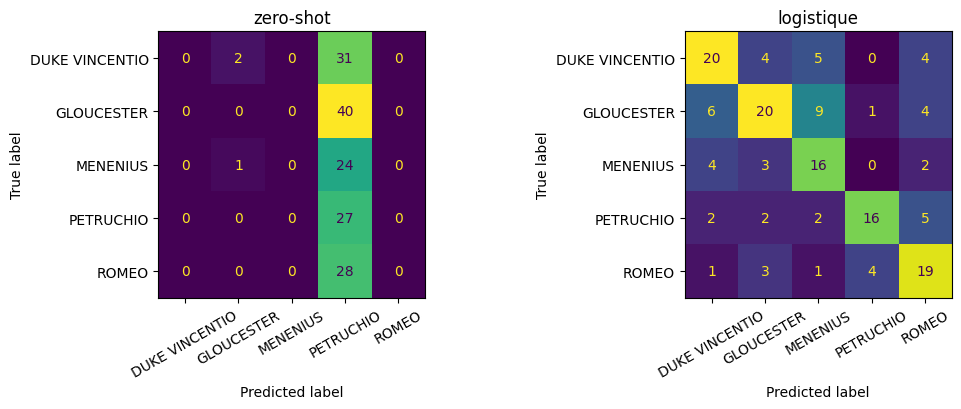

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, nom, pred in zip(axes, (retenu, "logistique"), (pred_test, pred_lr)):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, pred, labels=classes), display_labels=classes,
    ).plot(ax=ax, colorbar=False, xticks_rotation=30)
    ax.set_title(nom)
plt.tight_layout()
plt.show()

erreurs = pd.DataFrame({
    "réplique": X_test.to_numpy(),
    "vrai": y_test.to_numpy(),
    "llm": pred_test,
    "brut": brut_test,
})
erreurs = erreurs[erreurs["vrai"] != erreurs["llm"]].head(6)
print(erreurs.to_string(index=False))


## Bilan

Zero-shot retenu (F1 val 0,08, few-shot 0,07). Sur le test : 0,06, et la logistique est à 0,60.

Le modèle répond bien avec un nom de la liste, mais presque toujours `PETRUCHIO`. Les autres personnages ont un rappel de 0. Cinq exemples n'ont pas changé ça.

Sans étiquettes, un prompt permet d'essayer vite. Ici les étiquettes existent, et le petit modèle ne bat pas la logistique.
